***Full EDA & Vizualisation***
-load dataset
-check shape,columns,inforamtion(data type)
-check missing value , duplicated
-summary statistics (descriptive)
***Vizualisation***
    -scatter plot
    -Histograme 
    -countplot
    -boxplot
    -heatmap
***interpte insighte ***
 -summary insighte about EDA  
***Data preprocessing***
-Features selection 
-Train test split
-Handling missing value  (SimpleTmputer)
-outliers treatement 
-Encoder data catgorical
-Handling data imblaanced (SMOTE)
-Standardization (Scaler)

***Classification models***
-select model
-Training and evaluate it 
***Optimize model***
-Hyparameter tunig 
-PCA
***Results and summary ***
-Visualize resutls of Models
--adaptaion the best  model

In [1]:
import os 
os.environ['KAGGLE_API_TOKEN']='KGAT_5246f1ddd5b20b7c3dde82e3c19d8ab7'

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kaggle kernels pull umairziact/diabetes-dataset")

print("Path to dataset files:", path)

In [4]:
import shutil

shutil.copytree(
"C:/Users/hp/.cache/kagglehub/datasets/willianoliveiragibin/healthcare-insurance/versions/1",
"dataset",
dirs_exist_ok=True
)

'dataset'

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV,train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler,LabelEncoder,OrdinalEncoder
from sklearn.impute import SimpleImputer  
from imblearn.over_sampling import SMOTE
from collections import Counter


from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,classification_report

In [2]:
pd.set_option("display.max_columns",None)

EDA & Viz

In [3]:
df=pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0.0,33.6,0.627,50,1
1,1,85,66,29,0.0,26.6,0.351,31,0
2,8,183,64,0,0.0,23.3,0.672,32,1
3,1,89,66,23,94.0,28.1,0.167,21,0
4,0,137,40,35,168.0,43.1,1.200,33,1


EDA

In [4]:
print(df.shape)
print(df.columns)

(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(3), int64(6)
memory usage: 54.1 KB


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,73.652669,32.125065,0.458914,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,93.576029,7.049584,0.285596,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,13.350000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,318.125000,50.550000,1.200000,81.000000,1.000000


In [7]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
for col in df.columns:
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True))

Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
17      1
15      1
Name: count, dtype: int64
Pregnancies
1     0.175781
0     0.144531
2     0.134115
3     0.097656
4     0.088542
5     0.074219
6     0.065104
7     0.058594
8     0.049479
9     0.036458
10    0.031250
11    0.014323
13    0.013021
12    0.011719
14    0.002604
17    0.001302
15    0.001302
Name: proportion, dtype: float64
Glucose
99     17
100    17
111    14
125    14
129    14
       ..
56      1
169     1
149     1
65      1
190     1
Name: count, Length: 136, dtype: int64
Glucose
99     0.022135
100    0.022135
111    0.018229
125    0.018229
129    0.018229
         ...   
56     0.001302
169    0.001302
149    0.001302
65     0.001302
190    0.001302
Name: proportion, Length: 136, dtype: float64
BloodPressure
70     57
74     52
78     45
68     45
72     44
64     43
80     40
76     39
60     37
0

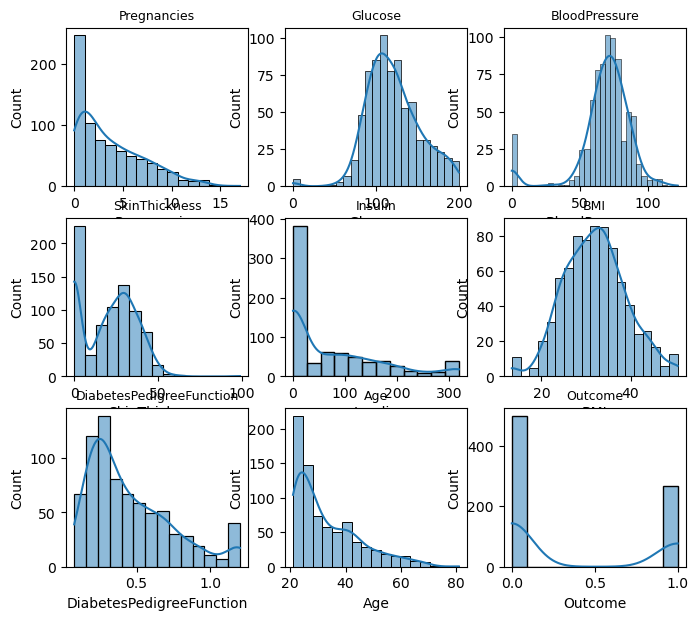

In [10]:
fig,axes=plt.subplots(3,3,figsize=(8,7))
axes=axes.flatten()
for i,col in enumerate(df.columns.values):
    sns.histplot(df[col],kde=True,ax=axes[i])
    axes[i].set_title(col,fontsize=9)
plt.show()

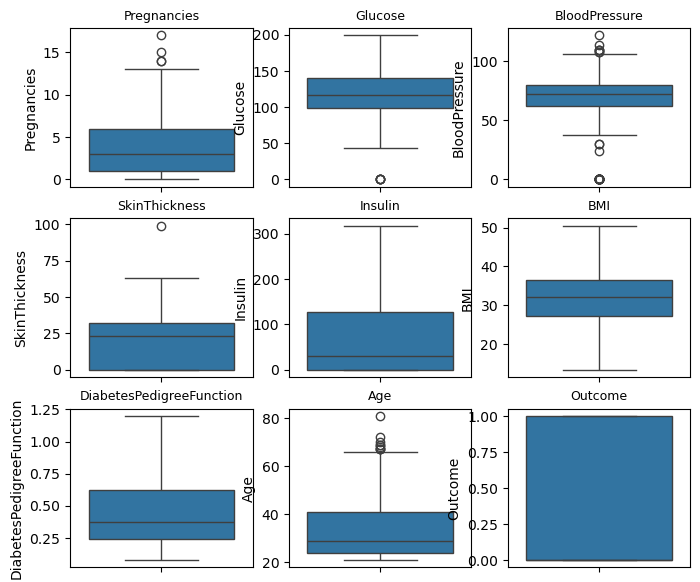

In [11]:
fig,axes=plt.subplots(3,3,figsize=(8,7))
axes=axes.flatten()
for i,col in enumerate(df.columns):
    sns.boxplot(df[col],ax=axes[i])
    axes[i].set_title(col,fontsize=9)
plt.show()

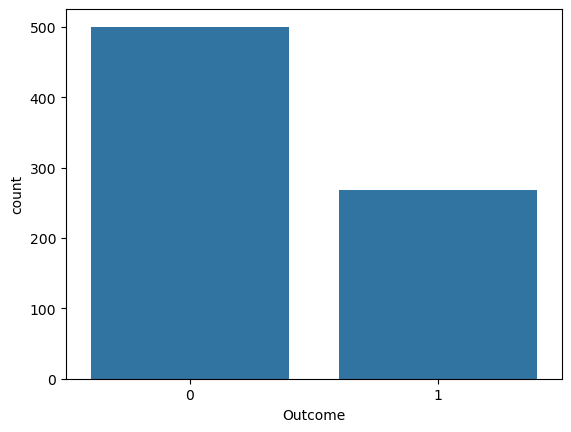

In [12]:
sns.countplot(x=df['Outcome'])
plt.show()

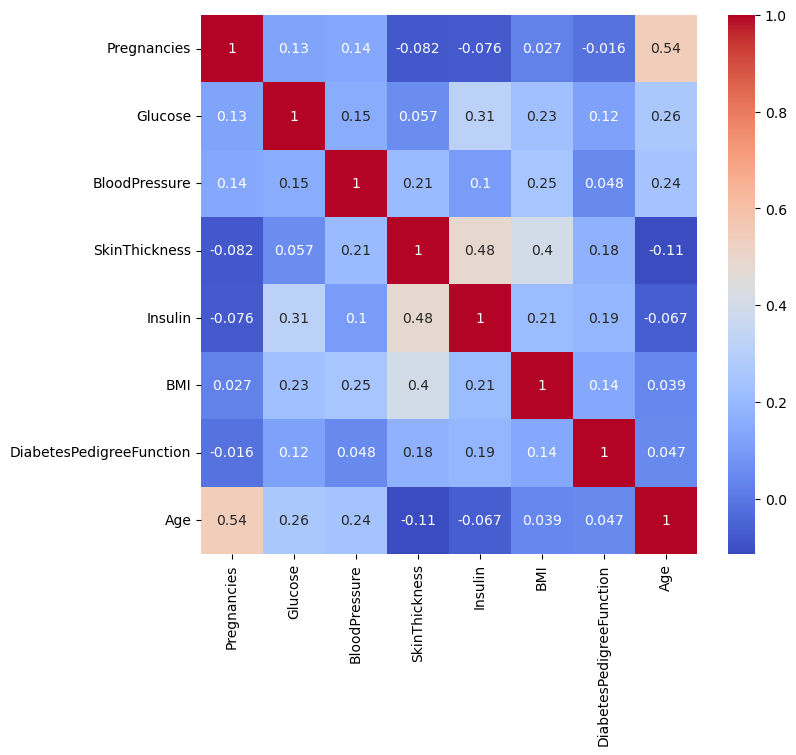

In [13]:
plt.figure(figsize=(8,7))
sns.heatmap(df.drop(columns=['Outcome']).corr(),annot=True,cmap='coolwarm')
plt.show()

In [14]:
# --- Handle BMI Outliers ---
q1_bmi = df['BMI'].quantile(0.25)
q3_bmi = df['BMI'].quantile(0.75)
iqr_bmi = q3_bmi - q1_bmi

lower_bmi = q1_bmi - 1.5 * iqr_bmi
upper_bmi = q3_bmi + 1.5 * iqr_bmi

df['BMI'] = np.where(df['BMI'] < lower_bmi, lower_bmi, 
                     np.where(df['BMI'] > upper_bmi, upper_bmi, df['BMI']))

# --- Handle Insulin Outliers ---
q1_Insulin = df['Insulin'].quantile(0.25)
q3_Insulin = df['Insulin'].quantile(0.75)
iqr_Insulin = q3_Insulin - q1_Insulin

lower_ch = q1_Insulin - 1.5 * iqr_Insulin
upper_ch = q3_Insulin + 1.5 * iqr_Insulin

# Cap Charges
df['Insulin'] = np.where(df['Insulin'] < lower_ch, lower_ch, 
                        np.where(df['Insulin'] > upper_ch, upper_ch, df['Insulin']))

# --- Handle DiabetesPedigreeFunction Outliers ---
q1_Insulin = df['DiabetesPedigreeFunction'].quantile(0.25)
q3_Insulin = df['DiabetesPedigreeFunction'].quantile(0.75)
iqr_Insulin = q3_Insulin - q1_Insulin

lower_ch = q1_Insulin - 1.5 * iqr_Insulin
upper_ch = q3_Insulin + 1.5 * iqr_Insulin

# Cap Charges
df['DiabetesPedigreeFunction'] = np.where(df['DiabetesPedigreeFunction'] < lower_ch, lower_ch, 
                        np.where(df['DiabetesPedigreeFunction'] > upper_ch, upper_ch, df['DiabetesPedigreeFunction']))



In [15]:
df.to_csv('diabetes.csv',index=False)

***EDA***
- No misssing value
- one rows duplicated
- labels are imbalanced  
- detect some outliers 
- correaltion is high > 0.95

Data preprocessing

In [24]:
df_copy=df.drop(columns=['Outcome'])
corr=df_copy.corr().abs()

to_drop=set()

for i in range(len(corr.columns)):
    for j in range(i):
        if corr.iloc[i,j] > 0.95:
            to_drop.add(corr.columns[i])
            
select_features=[c for c in df_copy.columns if c not in to_drop]

In [25]:
print(to_drop)
print("*"*40)
print(select_features)

set()
****************************************
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [26]:
X=df.drop(columns=['Outcome'])
y=df['Outcome']
 
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [29]:
print(x_train[:5])


     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  \
60             2       84              0              0    0.000  13.35   
618            9      112             82             24    0.000  28.20   
346            1      139             46             19   83.000  28.70   
294            0      161             50              0    0.000  21.90   
231            6      134             80             37  318.125  46.20   

     DiabetesPedigreeFunction  Age  
60                      0.304   21  
618                     1.200   50  
346                     0.654   22  
294                     0.254   65  
231                     0.238   46  


In [ ]:
print("Before SMOTE:", Counter(y_train))

smote = SMOTE(sampling_strategy='minority', random_state=42)
X_train, y_train = smote.fit_resample(x_train, y_train)

print("After SMOTE:", Counter(y_train))

Before SMOTE: Counter({0: 401, 1: 401})


In [47]:
scaler=StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled  = scaler.transform(x_test)

***Preprocessing***
-select all features beacause no-one > 0.95
-balanced labels

In [38]:
models={
    "LogisticRegression":LogisticRegression(),
    "SVM":SVC(),
    "KNN":KNeighborsClassifier(n_neighbors=3),
    "DecisionTree":DecisionTreeClassifier(random_state=42),
    "RandomForest":RandomForestClassifier(random_state=42),
    "GradientBoostingRegressor":GradientBoostingClassifier(random_state=42)
}

In [48]:
scores={}
for name,model in models.items():
  score=cross_val_score(model,X_train,y_train,cv=5)
  scores[name]=score.mean()

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

In [49]:
print("Name of model \t corss-validation ")
for name ,val in scores.items():
    print(f"{name} \t {val}")

Name of model 	 corss-validation 
LogisticRegression 	 0.7518400621118013
SVM 	 0.7381909937888198
KNN 	 0.7669099378881988
DecisionTree 	 0.7643478260869566
RandomForest 	 0.8342391304347826
GradientBoostingRegressor 	 0.8005512422360248


In [50]:
best_model=max(scores,key=scores.get)
print(f"best model is : {best_model}")

best model is : RandomForest


In [58]:
param_grid = {
    "RandomForest":{
                            'model__n_estimators': [50, 100, 200],
                            'model__max_depth': [3, 5, 7, None],
                            'model__max_features': ['sqrt', 'log2', None],
                            'model__min_samples_split': [2, 5, 10],
                            'model__min_samples_leaf': [1, 2, 4],
                            }
}
# scaling  + model 
pipe_line = Pipeline([
    ('scaler', StandardScaler()),
    ('model', models[best_model])
])

#GridSearchCV automates the hyperparameter tuning process and helps to find the best hyperparameters
grid_search = GridSearchCV(
    estimator=pipe_line,
    param_grid=param_grid[best_model],
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

In [ ]:
# grid_search.fit(X_train, y_train)
# print(grid_search.best_score_)
# print(grid_search.best_params_)

***Model Training***

***Evaluation***

In [155]:
y_train_pred = model.predict(x_train)
y_test_pred  = model.predict(x_test)

In [156]:
r2_train=r2_score(y_train,y_train_pred)
r2_test=r2_score(y_test,y_test_pred)

In [157]:
print(round(r2_train*100,2))
print(round(r2_test*100,2))

86.75
68.06


In [153]:
if r2_train < 0.85 and r2_test < 0.85:
    print("underfitting !!")
elif r2_train -r2_test > 0.05:
    print("overfitting !!")
else:
    print("Good fit !!")



underfitting !!


***Resutlts***
-best model is GradientBoostingRegressor
-model is overfitting(high trainnig , low testing )
-Use GridSearchCv to find best hyparameters 